1: Import the libraries and fix the random seed.

In [2]:
import importlib.util
import subprocess
import sys
from pathlib import Path
import warnings

if importlib.util.find_spec("category_encoders") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "category-encoders"])

if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
sns.set_theme(style="whitegrid")

from sklearn.metrics import f1_score

from course_helpers import PLOT_BLUE, PLOT_ORANGE

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
FIGSIZE = (6, 5)

TARGET = "repeat_purchase_90d"

DATA_DIR = Path(r"C:\Users\João Correia\Desktop\MasterDS\2026-27\semestre1\ML\2.Labs\Project\data") # Folder that holds the four CSV files

warnings.filterwarnings("ignore", category=FutureWarning)

ModuleNotFoundError: No module named 'course_helpers'

2: Load the tables and check if they fit together.

In [ ]:
train = pd.read_csv(DATA_DIR / "train.csv", parse_dates=["purchase_date"]).set_index("ID")
test = pd.read_csv(DATA_DIR / "test.csv", parse_dates=["purchase_date"]).set_index("ID")
clientes = pd.read_csv(DATA_DIR / "clientes.csv")
sample = pd.read_csv(DATA_DIR / "sample_submission.csv")

for name, frame in [("train", train), ("test", test), ("clientes", clientes)]:
    print(f"{name:9s} {frame.shape[0]:>5,} rows x {frame.shape[1]} columns")

print("\ntest IDs match sample_submission:", sample["ID"].tolist() == test.index.tolist())
print("columns only in train:", sorted(set(train.columns) - set(test.columns)))

train     6,534 rows x 38 columns
test        986 rows x 37 columns
clientes  1,143 rows x 13 columns

test IDs match sample_submission: True
columns only in train: ['repeat_purchase_90d']


<div class="alert alert-block alert-warning">

- Train has 6,534 rows;
- Test has 986 (about 15% of the size of train);
- Test ID's match the submission template in the same order, and the target is the only column missing from test.

</div>

3: Separate the column roles and look at the target.

In [ ]:
categorical = train.select_dtypes(include=["object", "string"]).columns.tolist()
numeric = [c for c in train.select_dtypes(include="number").columns if c != TARGET]

print(f"{len(numeric)} numeric columns:\n  {numeric}\n")
print(f"{len(categorical)} categorical columns:\n  {categorical}\n")

print(train[TARGET].value_counts()
      .to_frame("rows")
      .assign(share=lambda d: (d["rows"] / d["rows"].sum()).round(4)))

always_repeat = np.ones(len(train), dtype=int)
print(f"\nF1 of predicting 'repeat' for every row: {f1_score(train[TARGET], always_repeat):.4f}")

30 numeric columns:
  ['Total a Pagar', 'Total Bruto', 'Total Liquido', 'Total Imp_', 'Total Portes', 'Total Desc_ Global', 'Total Desc_ Linha', 'Custo', 'N_ Detalhes', 'invoice_count_current_purchase', 'days_since_previous_purchase', 'customer_tenure_days', 'prior_purchase_count', 'prior_total_spend', 'prior_mean_purchase_value', 'prior_std_purchase_value', 'prior_min_purchase_value', 'prior_max_purchase_value', 'prior_mean_gap_days', 'prior_std_gap_days', 'purchase_count_30d', 'spend_30d', 'purchase_count_90d', 'spend_90d', 'purchase_count_180d', 'spend_180d', 'purchase_count_365d', 'spend_365d', 'customer_id', 'random_noise']

6 categorical columns:
  ['payment_type', 'salesperson', 'commercial_zone', 'transport_method', 'warehouse', 'document_series']

                     rows   share
repeat_purchase_90d              
1                    3654  0.5592
0                    2880  0.4408

F1 of predicting 'repeat' for every row: 0.7173


<div class="alert alert-block alert-warning">

- 30 columns are stored as numbers;
- 6 cloumns are stored as text;
- 2 clomuns of numbers are not quantities (custumer_id) and (random_noise);
- The target is mildly imbalanced: 55.9% repeat, 44.1% not;
- F1 on the positive class, answering "repeat" for every row
  already scores F1 0.717.
  
</div>

4: Look at descriptive statistics.

In [ ]:
print(train[numeric].describe().T.round(2).to_string())
print()
print(train[categorical].describe().T.to_string())

                                 count        mean          std        min        25%        50%        75%           max
Total a Pagar                   6469.0      925.56      1335.00       0.93     188.92     476.74    1087.67  2.229721e+04
Total Bruto                     6469.0      886.15      1327.64       0.83     175.74     445.74    1036.70  2.157828e+04
Total Liquido                   6469.0      773.34      1136.36       0.76     154.38     389.91     903.37  1.812781e+04
Total Imp_                      6469.0      152.22       225.26       0.00      29.93      79.74     184.84  4.169400e+03
Total Portes                    6469.0        1.15         5.84       0.00       0.00       0.00       0.00  1.810600e+02
Total Desc_ Global              6469.0        0.35         5.12       0.00       0.00       0.00       0.00  2.184900e+02
Total Desc_ Linha               6469.0      112.47       289.99       0.00       0.00      13.13      92.28  4.103440e+03
Custo                   

<div class="alert alert-block alert-warning">

- Most columns have 6,469 values instead of 6,534;
- 65 rows are missing almost everything;
- Means far above medians (e.g. `Total a Pagar` 926 vs 477, `prior_total_spend` 18,908 vs 6,754) indicate strong right skew in money columns;
- Impossible extremes: `prior_mean_purchase_value` reaches 1e9 and goes negative, and day counts reach -4;
- A handful of such values inflate the mean of `prior_mean_purchase_value` to 2.8 million while its median stays at 725;
- Near-constant columns: `Total Portes` and `Total Desc_ Global` are 0 in over 75% of rows, `invoice_count_current_purchase` is almost always 1, `commercial_zone` has one level in 97% of rows and `warehouse` one level in 99.7%. They are likely to carry little information;
- `transport_method` has 80 levels, many of them rare.

</div>

5: Looking at Missing values, in train and test side by side.

In [ ]:
missing = (pd.DataFrame({"train gaps": train.isna().sum(),
                         "train %": (train.isna().mean() * 100).round(2),
                         "test gaps": test.isna().sum(),
                         "test %": (test.isna().mean() * 100).round(2),})
           .query("`train gaps` > 0")
           .sort_values("train gaps", ascending=False))
print(missing.to_string())

gaps_per_row_train = train.isna().sum(axis=1)
print("\nrows by number of  train gaps:")
print(gaps_per_row_train.value_counts().sort_index().to_string())

gaps_per_row_test = test.isna().sum(axis=1)
print("\nrows by number of  test gaps:")
print(gaps_per_row_test.value_counts().sort_index().to_string())

                                train gaps  train %  test gaps  test %
prior_std_gap_days                    1478    22.62       69.0    7.00
prior_mean_gap_days                   1308    20.02       76.0    7.71
prior_std_purchase_value              1113    17.03       46.0    4.67
prior_mean_purchase_value              862    13.19       52.0    5.27
days_since_previous_purchase           861    13.18       52.0    5.27
prior_max_purchase_value               668    10.22       22.0    2.23
prior_min_purchase_value               668    10.22       22.0    2.23
transport_method                       261     3.99       30.0    3.04
spend_365d                             260     3.98       30.0    3.04
payment_type                           260     3.98       30.0    3.04
warehouse                              260     3.98       30.0    3.04
salesperson                            259     3.96       30.0    3.04
Total Desc_ Global                      65     0.99        0.0    0.00
Total 

In [ ]:
empty_rows = gaps_per_row_train >= train.shape[1] - 5
print(f"{empty_rows.sum()} nearly empty rows")
print("columns still filled in them:",
      train.loc[empty_rows].notna().sum()[lambda s: s > 0].to_dict())

print(f"\nduplicated rows (extra copies): {train.duplicated().sum()}")
print(f"rows involved in a duplication: {train.duplicated(keep=False).sum()}")

filled = train.loc[~empty_rows]
print(f"duplicates once the empty rows are set aside:", filled.duplicated().sum())

65 nearly empty rows
columns still filled in them: {'repeat_purchase_90d': 65, 'customer_id': 65}

duplicated rows (extra copies): 10
rows involved in a duplication: 16
duplicates once the empty rows are set aside: 0


<div class="alert alert-block alert-warning">

- 65 rows are empty records, and they explain the duplicates. They keep only `customer_id` and the `target`; every one of the 36 other columns is missing;
- The test file has no such row: every column with exactly 65 gaps in train has 0 gaps in test;
- The 10 "duplicates" are these same empty rows.

</div>

6: Test if the remaining gaps are not all of one kind.

In [ ]:
history = (filled["prior_purchase_count"].clip(upper=3).astype(int)
           .map({0: "0", 1: "1", 2: "2", 3: "3+"}))
prior_cols = ["days_since_previous_purchase", "prior_mean_purchase_value",
              "prior_min_purchase_value", "prior_max_purchase_value",
              "prior_std_purchase_value", "prior_mean_gap_days", "prior_std_gap_days"]

print("\n% missing by number of previous purchases:")
print(filled[prior_cols].isna().groupby(history).mean().mul(100).round(1).T.to_string())

print("\nrepeat rate by number of previous purchases:")
print(filled.groupby(history)[TARGET].agg(rows="size", repeat_rate="mean").round(3).to_string())


% missing by number of previous purchases:
prior_purchase_count              0      1      2   3+
days_since_previous_purchase  100.0    4.3    5.5  3.0
prior_mean_purchase_value     100.0    4.5    3.0  3.2
prior_min_purchase_value      100.0    0.0    0.0  0.0
prior_max_purchase_value      100.0    0.0    0.0  0.0
prior_std_purchase_value      100.0  100.0    0.0  0.0
prior_mean_gap_days           100.0  100.0    5.8  3.4
prior_std_gap_days            100.0  100.0  100.0  0.0

repeat rate by number of previous purchases:
                      rows  repeat_rate
prior_purchase_count                   
0                      603        0.333
1                      445        0.373
2                      365        0.400
3+                    5056        0.615


<div class="alert alert-block alert-warning">

- We find three kinds of missing values:

1. Structural: With 0 previous purchases every `prior_*` column is 100% missing; with 1, the standard deviations are 100% missing; with 2, the standard deviation of the gaps is 100% missing;
`prior_purchase_count` stays, and history flags (e.g. `has_history = prior_purchase_count > 0`) are derived by a fixed rule, which learns nothing from the data and can therefore be applied to train and test alike;
The history is predictive: first-time buyers repeat 33% of the time, customers with 3+ purchases 62%.
2. Random: 3-5% of rows with enough history still miss `days_since_previous_purchase`, `prior_mean_purchase_value` or `prior_mean_gap_days`. These are genuinely unknown and are imputed;
Some can be recomputed exactly, e.g. `prior_mean = prior_total_spend / prior_purchase_count`;
3. A ~4% block in `spend_365d`, `payment_type`, `salesperson`, `transport_method` and `warehouse`, present in test too (30 rows each).

</div>

7: Look at Implausible values.

In [ ]:
for column in [c for c in numeric if c != "random_noise"]:
    flags = {split: {"== 1e9": int((frame[column] >= 1e9).sum()),
                     "< 0": int((frame[column] < 0).sum())}
             for split, frame in [("train", train), ("test", test)]}
    if any(flags["train"].values()):
        print(f"{column:30s} train {flags['train']}  test {flags['test']}")

days_since_previous_purchase   train {'== 1e9': 0, '< 0': 16}  test {'== 1e9': 0, '< 0': 2}
prior_mean_purchase_value      train {'== 1e9': 16, '< 0': 16}  test {'== 1e9': 2, '< 0': 2}
prior_mean_gap_days            train {'== 1e9': 0, '< 0': 16}  test {'== 1e9': 0, '< 0': 2}
spend_365d                     train {'== 1e9': 15, '< 0': 15}  test {'== 1e9': 2, '< 0': 2}


8: Look the Internal consistency.

In [ ]:
f = filled
has_mean = f["prior_mean_purchase_value"].notna() & (f["prior_purchase_count"] > 0)
has_365 = f["spend_365d"].notna()
has_prev = f["days_since_previous_purchase"].notna()

checks = {
    "prior_mean = prior_total_spend / prior_purchase_count":
        np.isclose(f.loc[has_mean, "prior_mean_purchase_value"],
                   f.loc[has_mean, "prior_total_spend"] / f.loc[has_mean, "prior_purchase_count"],
                   atol=0.05).mean(),

    "prior_min <= prior_mean <= prior_max":
        ((f["prior_min_purchase_value"] <= f["prior_mean_purchase_value"] + 0.01)
         & (f["prior_mean_purchase_value"] <= f["prior_max_purchase_value"] + 0.01))[has_mean].mean(),

    "prior_max <= prior_total_spend":
        (f["prior_max_purchase_value"] <= f["prior_total_spend"] + 0.01)[f["prior_max_purchase_value"].notna()].mean(),
    "purchase counts nested (30d <= 90d <= 180d <= 365d)":
        ((f["purchase_count_30d"] <= f["purchase_count_90d"])
         & (f["purchase_count_90d"] <= f["purchase_count_180d"])
         & (f["purchase_count_180d"] <= f["purchase_count_365d"])).mean(),
    "spend nested (30d <= 90d <= 180d <= 365d)":
        ((f["spend_30d"] <= f["spend_90d"] + 0.01)
         & (f["spend_90d"] <= f["spend_180d"] + 0.01)
         & (f["spend_180d"] <= f["spend_365d"] + 0.01))[has_365].mean(),
    "customer_tenure_days >= days_since_previous_purchase":
        (f["customer_tenure_days"] >= f["days_since_previous_purchase"])[has_prev].mean(),
    "Total a Pagar = Liquido + Imp + Portes":
        np.isclose(f["Total a Pagar"],
                   f["Total Liquido"] + f["Total Imp_"] + f["Total Portes"], atol=0.05).mean(),
}
for rule, share in checks.items():
    print(f"{share:7.1%}  {rule}")

  98.6%  prior_mean = prior_total_spend / prior_purchase_count
  98.6%  prior_min <= prior_mean <= prior_max
  99.2%  prior_max <= prior_total_spend
 100.0%  purchase counts nested (30d <= 90d <= 180d <= 365d)
  99.8%  spend nested (30d <= 90d <= 180d <= 365d)
 100.0%  customer_tenure_days >= days_since_previous_purchase
  83.7%  Total a Pagar = Liquido + Imp + Portes


<div class="alert alert-block alert-warning">

- The count windows are well nested (100%) and tenure always covers the days since the previous purchase (100%), so these columns are reliable;
- `prior_mean = prior_total_spend / prior_purchase_count` fails in 1.4% of rows (78). Only 32 of them are the 1e9 and negative; the other 46 are means inflated;
- `prior_max <= prior_total_spend` fails in 0.8% of rows (45): a single previous purchase larger than the sum of all previous purchases, which is impossible;
- `prior_min <= prior_mean <= prior_max` fails in 1.4%, the same corrupted rows. Spend nesting fails in 0.2%: the negative and 1e9 values of `spend_365d`;
- `Total a Pagar = Liquido + Imp + Portes` holds in only 83.7% of rows. Probably this is not an error that can be corrected (the amounts may include other charges).

</div>

9: Find Identifier-like columns.

In [ ]:
print("ID unique per row:", train.index.is_unique)
print("distinct customers in train:", filled["customer_id"].nunique())

print("\ncorrelation with the target:")
print(filled[["customer_id", "random_noise"]].corrwith(filled[TARGET]).round(4).to_string())

print("\nrows per customer:")
print(filled.groupby("customer_id").size().describe().round(1).to_string())

ID unique per row: True
distinct customers in train: 607

correlation with the target:
customer_id    -0.1112
random_noise   -0.0120

rows per customer:
count    607.0
mean      10.7
std       19.8
min        1.0
25%        1.0
50%        4.0
75%       12.0
max      276.0


10: Compare train with test.

In [ ]:
print("purchase dates")
print(pd.DataFrame({"train": train["purchase_date"].agg(["min", "max"]),
                    "test": test["purchase_date"].agg(["min", "max"])}).to_string())

seen = test["customer_id"].isin(train["customer_id"])
print(f"\ntest rows whose customer also appears in train: {seen.mean():.1%}")
print(f"test customers: {test['customer_id'].nunique()},"
      f" of which seen in train: {test.loc[seen, 'customer_id'].nunique()}")

print("\nlevels in test that never occur in train:")
for column in categorical:
    unseen = sorted(set(test[column].dropna()) - set(train[column].dropna()))
    if unseen:
        print(f"  {column}: {unseen}")

purchase dates
         train       test
min 2015-07-11 2025-05-24
max 2025-02-15 2026-10-06

test rows whose customer also appears in train: 94.5%
test customers: 206, of which seen in train: 184

levels in test that never occur in train:
  payment_type: ['Maybe Tomorrow Payment 1', 'Maybe Tomorrow Payment 5', 'Maybe Tomorrow Payment 6']
  commercial_zone: ['Decorative Dashboard Zone 1', 'Decorative Dashboard Zone 5']
  transport_method: ['Maybe Tomorrow Delivery 54', 'Maybe Tomorrow Delivery 65']
  warehouse: ['Final Excel Warehouse 2']


<div class="alert alert-block alert-warning">

- Test is later in time. Train runs from July 2015 to February 2025; test from May 2025 to October 2026. The task is to predict the future from the past;
- Customers repeat. Each customer has on average 10.7 training rows (median 4, maximum 276), and 94.5% of test rows belong to customers already seen in train (184 of 206);
- We have to be aware, in validation, a random split places rows of the same customer and of the same period in both training and validation folds, and ignores that test lies after train, so its score may be optimistic;
- `purchase_date` is not used as a raw feature. Every test date lies after the last training date, so a model would have to extrapolate on it;
- Unseen levels. `payment_type`, `commercial_zone`, `transport_method` and `warehouse` have levels in test that never occur in train. The encoder must ignore unknown levels instead of failing;
- `customer_id` and `random_noise` are excluded;
- `customer_id` correlates with the target (-0.11) only through how numbers were assigned.

</div>

11: Lool into table `clientes.csv`.

In [ ]:
print("every train customer is in clientes:",
      set(train["customer_id"]) <= set(clientes["customer_id"]))
print("every test customer is in clientes: ",
      set(test["customer_id"]) <= set(clientes["customer_id"]))
print("customer_id unique in clientes:     ", clientes["customer_id"].is_unique)

profile = pd.DataFrame({"% missing": clientes.isna().mean().mul(100).round(1),
                        "unique values": clientes.nunique(),
                        "example": clientes.iloc[0]})
print()
print(profile.to_string())

every train customer is in clientes: True
every test customer is in clientes:  True
customer_id unique in clientes:      True

                     % missing  unique values                                  example
customer_id                0.0           1143                                   842570
country_or_region          0.0             11  Country CT11: Land of The Final Version
commercial_region         10.0             37           Region RG37: We Will See Later
island                    50.6             10                                      NaN
municipality              13.9            183                                      NaN
city                      47.8            417            City CY417: Missing Cell Port
postal_area                6.2            271                                      NaN
postal_code               14.9            828  Postal code PC828: #REF! Delivery Route
street                    52.3            511                                      NaN
add

<div class="alert alert-block alert-warning">

- The join is safe: every customer in train and test is present and the key is unique;
- `customer_type` is 100% empty;
- `company_name` (1,141 values) and `address` (1,120) have essentially one value per customer;
- `island`, `city` and `street` are about 50% empty;
- `postal_code` and `municipality` are high-cardinality;
- Only a few low-cardinality, well-filled columns are worth testing: `country_or_region`, `commercial_region` and `customer_since_year`.

</div>

12: Finde if are the impossible values concentrated in a few broken rows, or spread out?

In [ ]:
anomalies = pd.DataFrame({
    "days_since_prev < 0":    filled["days_since_previous_purchase"] < 0,
    "prior_mean_gap < 0":     filled["prior_mean_gap_days"] < 0,
    "prior_mean_value < 0":   filled["prior_mean_purchase_value"] < 0,
    "prior_mean_value = 1e9": filled["prior_mean_purchase_value"] >= 1e9,
    "spend_365d < 0":         filled["spend_365d"] < 0,
    "spend_365d = 1e9":       filled["spend_365d"] >= 1e9,
    "prior_mean_value inflated": (filled["prior_mean_purchase_value"].between(0, 1e9, inclusive="neither")
                                  & (filled["prior_mean_purchase_value"]
                                     > 2 * filled["prior_total_spend"] / filled["prior_purchase_count"])),
    "prior_max > prior_total":   filled["prior_max_purchase_value"] > filled["prior_total_spend"] + 0.01,
})
print(anomalies.sum().to_string())
print("\nrows with at least one anomaly:", anomalies.any(axis=1).sum())
print("rows with two or more:          ", (anomalies.sum(axis=1) >= 2).sum())

print("\ndistinct negative values of days_since_previous_purchase:",
      sorted(filled.loc[anomalies["days_since_prev < 0"], "days_since_previous_purchase"].unique()))

print("rows where spend_365d < 0 while spend_180d >= 0:",
      ((filled["spend_365d"] < 0) & (filled["spend_180d"] >= 0)).sum())

# How far off are the inflated means? Real values are stored with 2 decimals.
inflated = filled.loc[anomalies["prior_mean_value inflated"]]
ratio = inflated["prior_mean_purchase_value"] / (inflated["prior_total_spend"] / inflated["prior_purchase_count"])
print("\ninflated means, ratio to total / count:", ratio.describe()[["min", "50%", "max"]].round(1).to_dict())
print(inflated[["prior_mean_purchase_value", "prior_total_spend", "prior_purchase_count"]].head(3))

t = test
test_flags = {
    "prior_mean_value inflated": (t["prior_mean_purchase_value"].between(0, 1e9, inclusive="neither")
                                  & (t["prior_mean_purchase_value"]
                                     > 2 * t["prior_total_spend"] / t["prior_purchase_count"])).sum(),
    "prior_max > prior_total": (t["prior_max_purchase_value"] > t["prior_total_spend"] + 0.01).sum(),
}
print("\nsame outliers in test:", {k: int(v) for k, v in test_flags.items()})

days_since_prev < 0          16
prior_mean_gap < 0           16
prior_mean_value < 0         16
prior_mean_value = 1e9       16
spend_365d < 0               15
spend_365d = 1e9             15
prior_mean_value inflated    46
prior_max > prior_total      45

rows with at least one anomaly: 184
rows with two or more:           1

distinct negative values of days_since_previous_purchase: [np.float64(-4.0)]
rows where spend_365d < 0 while spend_180d >= 0: 15

inflated means, ratio to total / count: {'min': 8.5, '50%': 16.1, 'max': 24.8}
          prior_mean_purchase_value  prior_total_spend  prior_purchase_count
ID                                                                          
10000556               13325.783819           11589.56                   9.0
10000712               11142.309979            7390.05                  16.0
10000733               11047.015485          150673.10                 173.0

same outliers in test: {'prior_mean_value inflated': 7, 'prior_max > prior_t

<div class="alert alert-block alert-warning">

The impossible values are isolated, injected errors. 184 rows (2.8%) carry a bad value and all but one carry exactly one. There are three kinds:

- Sentinels: `1e9` in `prior_mean_purchase_value` and `spend_365d`;
- Impossible negatives in four columns. Every negative day count is exactly -4, and every negative `spend_365d` sits next to a non-negative `spend_180d`: not natural errors.
- Hidden outliers: 46 means inflated 8-25 times relative to total / count, and 45 maxima larger than the total spend;

The rest of each row is valid, so these cells are set to missing and then imputed (or recomputed: `prior_mean = prior_total_spend / prior_purchase_count`);

- Test contains the same errors (2 per sentinel/negative column, 7 inflated means, 6 impossible maxima).

</div>

13: Look at Univariate distributions.

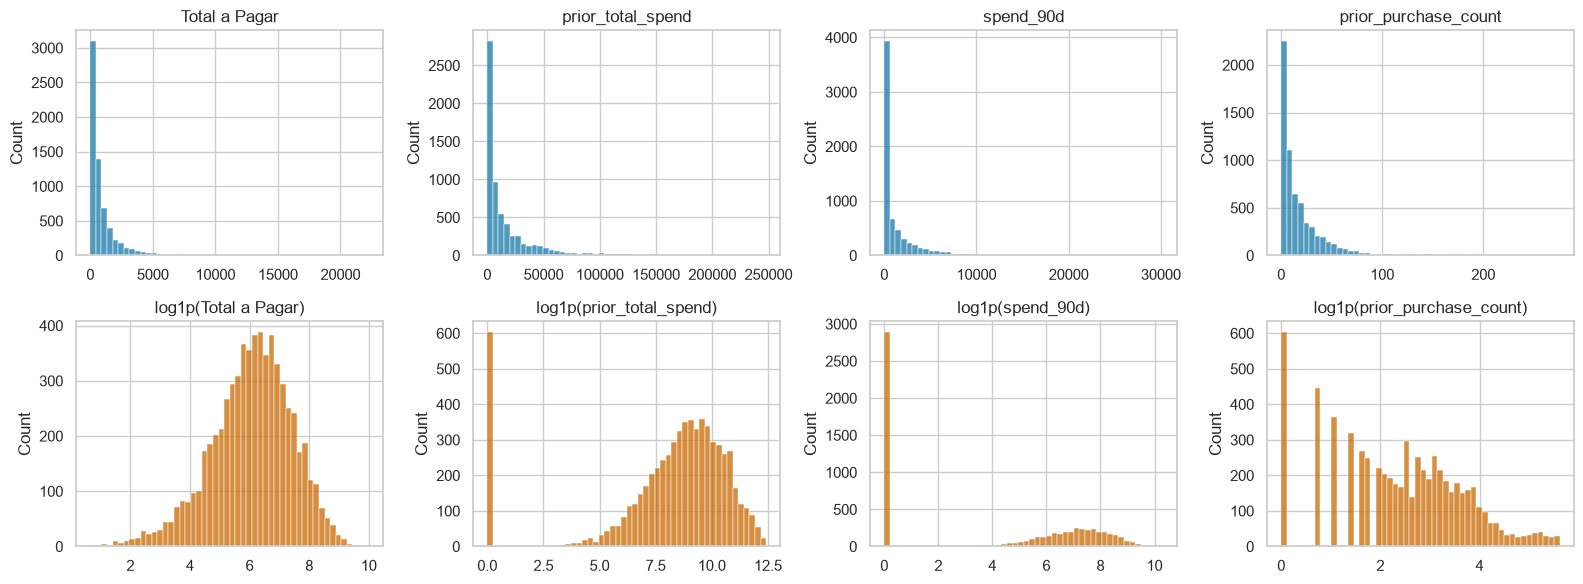

most skewed columns:
Total Desc_ Global              27.5
prior_max_purchase_value        21.3
spend_365d                      20.4
Total Portes                    19.5
prior_mean_purchase_value       18.8
prior_mean_gap_days              9.3
prior_std_gap_days               7.8
days_since_previous_purchase     6.5


In [ ]:
money = ["Total a Pagar", "prior_total_spend", "spend_90d", "prior_purchase_count"]

fig, axes = plt.subplots(2, len(money), figsize=(4 * len(money), 6))
for i, col in enumerate(money):
    sns.histplot(filled[col], bins=50, ax=axes[0, i], color=PLOT_BLUE)
    sns.histplot(np.log1p(filled[col]), bins=50, ax=axes[1, i], color=PLOT_ORANGE)
    axes[0, i].set_title(col)
    axes[1, i].set_title(f"log1p({col})")
    axes[0, i].set_xlabel("")
    axes[1, i].set_xlabel("")
plt.tight_layout()
plt.show()

print("most skewed columns:")
print(filled[numeric].skew().sort_values(ascending=False).round(1).head(8).to_string())

<div class="alert alert-block alert-warning">

- Money and count columns are concentrated near zero with long right tails (skewness up to 27);
- After `log1p` the distributions become roughly symmetric.

</div>

14: Categorical columns against the target.

In [ ]:
for col in categorical:
    table = (filled.groupby(col, dropna=False)[TARGET]
             .agg(rows="size", repeat_rate="mean")
             .sort_values("rows", ascending=False).round(3))
    print(f"\n{col} ({filled[col].nunique()} levels)")
    print(table.head(6).to_string())


payment_type (9 levels)
                           rows  repeat_rate
payment_type                                
Maybe Tomorrow Payment 7   4565        0.527
Maybe Tomorrow Payment 12   991        0.543
Maybe Tomorrow Payment 9    502        0.950
NaN                         195        0.564
Maybe Tomorrow Payment 10   134        0.403
Maybe Tomorrow Payment 8     40        0.325

salesperson (9 levels)
                  rows  repeat_rate
salesperson                        
VLOOKUP Master 1  4054        0.624
VLOOKUP Master 4  1461        0.394
VLOOKUP Master 9   384        0.547
VLOOKUP Master 7   201        0.483
NaN                194        0.598
VLOOKUP Master 2   123        0.602

commercial_zone (5 levels)
                             rows  repeat_rate
commercial_zone                               
Decorative Dashboard Zone 4  6260        0.565
Decorative Dashboard Zone 2   151        0.411
Decorative Dashboard Zone 3    56        0.357
Decorative Dashboard Zone 6     1       

<div class="alert alert-block alert-warning">

- `payment_type = Payment 9` repeats 95% of the time on 502 rows, against 53-54% for the two most common types: the strongest categorical signal;
- `salesperson` separates well: Master 1 (4,054 rows) 62% vs Master 4 (1,461 rows) 39%;
- `document_series` is flat (about 56% in every level);
- `commercial_zone` and `warehouse` are almost constant, with levels of 1 row (0% rate, not evidence);
- `transport_method` has 80 levels;
- Missing categories repeat at about the overall rate (56-64%).

</div>

15: Look at Numeric columns by class.

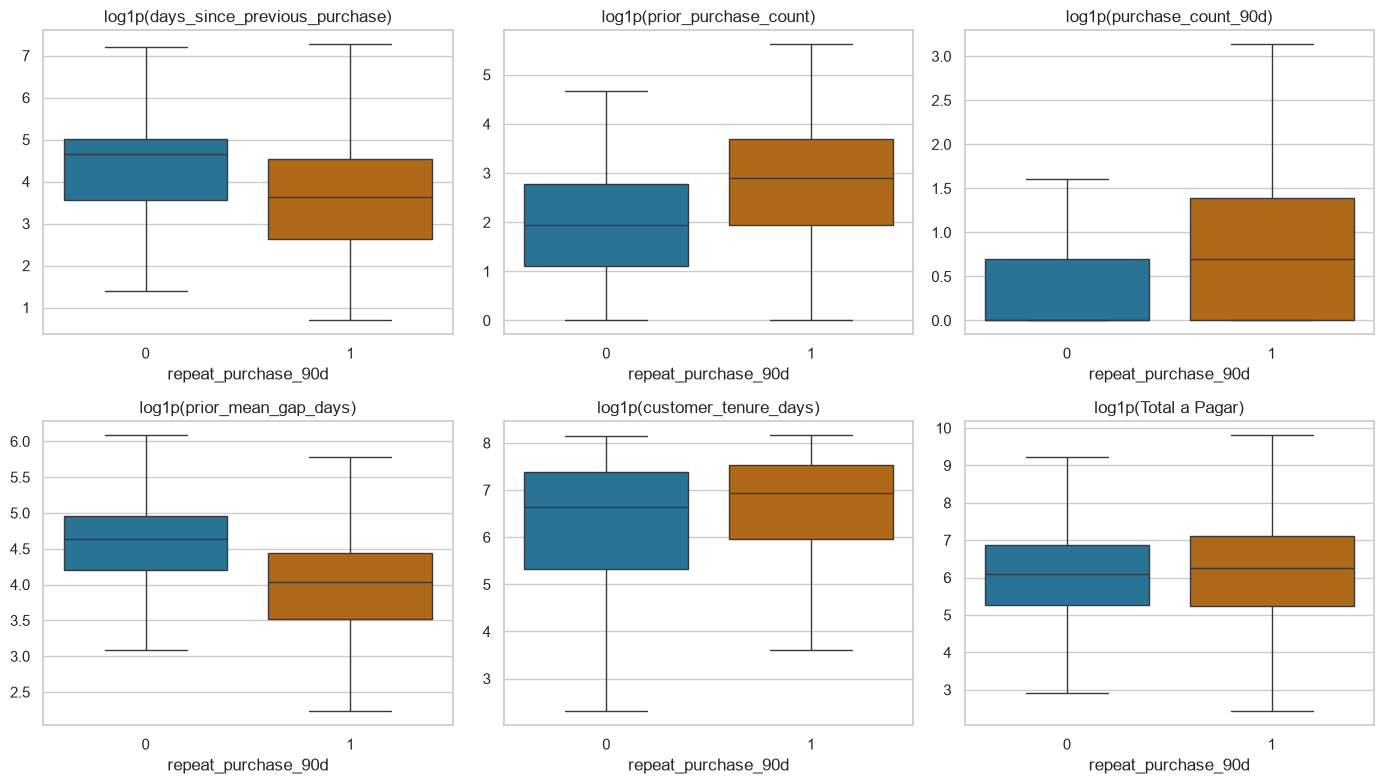

median by class:
repeat_purchase_90d               0       1
days_since_previous_purchase  105.0    37.0
prior_purchase_count            6.0    17.0
purchase_count_90d              0.0     1.0
prior_mean_gap_days           101.6    55.8
customer_tenure_days          769.0  1024.0
Total a Pagar                 443.4   520.0


In [ ]:
key = ["days_since_previous_purchase", "prior_purchase_count", "purchase_count_90d",
       "prior_mean_gap_days", "customer_tenure_days", "Total a Pagar"]
clean = filled.loc[~anomalies.any(axis=1)]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.ravel(), key):
    sns.boxplot(x=clean[TARGET], y=np.log1p(clean[col]), ax=ax, showfliers=False,
                hue=clean[TARGET], palette=[PLOT_BLUE, PLOT_ORANGE], legend=False)
    ax.set_title(f"log1p({col})")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

print("median by class:")
print(clean.groupby(TARGET)[key].median().T.round(1).to_string())

<div class="alert alert-block alert-warning">

- Customers who repeat bought more recently (median 37 vs 105 days since the previous purchase), more often (17 vs 6 previous purchases) and at shorter intervals (56 vs 102 days);
- The value of the current order hardly differs between classes (520 vs 443);
- Repeat purchase is a matter of frequency and recency of the relationship, not of the size of this order.

</div>

16: Multivariate view.

In [ ]:
cols = [c for c in numeric if c != "customer_id"] + [TARGET]
corr = clean[cols].corr(method="spearman")

plt.figure(figsize=(14, 12))
mask = np.triu(np.ones_like(corr.corr(method='spearman', dtype=bool)))
sns.heatmap(corr, cmap="RdBu_r", mask=mask,center=0, vmin=-1, vmax=1, square=True,
            cbar_kws={"shrink": 0.6})
plt.title("Spearman correlation (training rows without anomalies)")
plt.tight_layout()
plt.show()

features_corr = corr.drop(index=TARGET, columns=TARGET)
upper = features_corr.where(np.triu(np.ones(features_corr.shape, dtype=bool), k=1))
pairs = upper.stack().loc[lambda s: s.abs() >= 0.9].sort_values(ascending=False)
print(f"{len(pairs)} pairs with |rho| >= 0.9:")
print(pairs.round(3).to_string())

print("\ncorrelation with the target:")
print(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3).to_string())

NameError: name 'numeric' is not defined

<div class="alert alert-block alert-warning">

- Redundant blocks. `Total a Pagar`, `Total Bruto` and `Total Liquido` (rho >= 0.99); count and spend in the same window (0.91-0.97); `prior_purchase_count` and `prior_total_spend` (0.90); `prior_std_purchase_value` and `prior_max_purchase_value` (0.94);
- What drives the target. History and recency: purchase counts in the windows (0.39-0.44), mean gap between purchases (-0.42), days since the previous purchase (-0.31).Current-order amounts barely relate (|rho| < 0.08);
- `random_noise` sits at -0.007, the reference for "no relation".

</div>

17: Look at Stability over time.

In [ ]:
# Is the outcome stable over time? Test lies after the last training date.
print(filled.groupby(filled["purchase_date"].dt.year)[TARGET]
      .agg(rows="size", repeat_rate="mean").round(3).T.to_string())

purchase_date     2015     2016     2017     2018     2019     2020     2021     2022     2023     2024    2025
rows           335.000  420.000  670.000  716.000  646.000  670.000  782.000  628.000  767.000  757.000  78.000
repeat_rate      0.534    0.514    0.633    0.538    0.522    0.594    0.549    0.481    0.581    0.602   0.628


<div class="alert alert-block alert-warning">

- The repeat rate moves between 48% and 63% with no trend, so the relation between features and target should hold in the test period;
- 2025 has only 78 rows, so its 63% is not a reliable estimate.

</div>